In [1]:
import pandas as pd, numpy as np, matplotlib
print(pd.__version__, np.__version__, matplotlib.__version__)

2.3.3 2.3.5 3.10.6


In [2]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt

# ctr, cpc (Rs), conversion rate, avg order value (Rs)
PLATFORMS = {
    "Facebook":  (0.012, 18, 0.025, 3200),
    "Instagram": (0.015, 22, 0.030, 3500),
    "Google":    (0.035, 30, 0.050, 4000),
    "TikTok":    (0.020, 12, 0.012, 2500),
    "YouTube":   (0.008, 15, 0.018, 3000),
}

def generate_data(n, seed=42):
    rng = np.random.default_rng(seed)
    names = np.array(list(PLATFORMS))
    params = np.array(list(PLATFORMS.values()))
    idx = rng.integers(0, 5, n)

    impressions = rng.integers(1000, 50000, n)
    ctr  = params[idx, 0] * rng.uniform(0.7, 1.3, n)
    clicks = rng.binomial(impressions, ctr)
    spend = clicks * params[idx, 1] * rng.uniform(0.7, 1.3, n)
    conversions = rng.binomial(clicks, params[idx, 2] * rng.uniform(0.7, 1.3, n))
    revenue = conversions * params[idx, 3] * rng.uniform(0.7, 1.3, n)

    return pd.DataFrame({
        "date": pd.to_datetime("2024-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
        "campaign": "Camp_" + rng.integers(1, 21, n).astype(str),
        "platform": names[idx],
        "impressions": impressions, "clicks": clicks,
        "spend": spend.round(2), "conversions": conversions,
        "revenue": revenue.round(2),
        "age": rng.choice(["18-24","25-34","35-44","45-54","55+"], n, p=[.3,.35,.2,.1,.05]),
        "gender": rng.choice(["Male","Female"], n),
        "city": rng.choice(["Lahore","Karachi","Islamabad","Faisalabad","Multan","Peshawar"], n),
        "device": rng.choice(["Mobile","Desktop","Tablet"], n, p=[.7,.25,.05]),
    })

df = generate_data(10_000)
df.head()

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2024-12-21,Camp_14,Facebook,17596,234,3421.58,8,23677.20,25-34,Male,Peshawar,Desktop
1,2024-10-29,Camp_5,TikTok,11689,278,4243.03,1,1924.32,45-54,Male,Multan,Mobile
2,2024-01-21,Camp_14,TikTok,26496,449,6999.75,1,3071.60,35-44,Male,Multan,Mobile
3,2024-10-03,Camp_2,Google,33483,823,25817.58,49,200795.02,25-34,Male,Islamabad,Desktop
4,2024-02-29,Camp_16,Google,13809,417,10161.77,29,134728.39,18-24,Female,Islamabad,Mobile


In [3]:
def add_metrics(d):
    d = d.copy()
    d["CTR"] = d["clicks"] / d["impressions"]
    d["CPC"] = d["spend"] / d["clicks"].replace(0, np.nan)
    d["CPA"] = d["spend"] / d["conversions"].replace(0, np.nan)
    d["CVR"] = d["conversions"] / d["clicks"].replace(0, np.nan)
    d["ROAS"] = d["revenue"] / d["spend"].replace(0, np.nan)
    return d

df = add_metrics(df)
df.head()

,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device,CTR,CPC,CPA,CVR,ROAS
0,2024-12-21,Camp_14,Facebook,17596,234,3421.58,8,23677.20,25-34,Male,Peshawar,Desktop,0.013298,14.622137,427.697500,0.034188,6.919961
1,2024-10-29,Camp_5,TikTok,11689,278,4243.03,1,1924.32,45-54,Male,Multan,Mobile,0.023783,15.262698,4243.030000,0.003597,0.453525
2,2024-01-21,Camp_14,TikTok,26496,449,6999.75,1,3071.60,35-44,Male,Multan,Mobile,0.016946,15.589644,6999.750000,0.002227,0.438816
3,2024-10-03,Camp_2,Google,33483,823,25817.58,49,200795.02,25-34,Male,Islamabad,Desktop,0.024580,31.370085,526.889388,0.059538,7.777453
4,2024-02-29,Camp_16,Google,13809,417,10161.77,29,134728.39,18-24,Female,Islamabad,Mobile,0.030198,24.368753,350.405862,0.069544,13.258359


In [4]:
def platform_summary(d):
    g = d.groupby("platform")[["impressions","clicks","spend","conversions","revenue"]].sum()
    g["CTR"]  = g.clicks / g.impressions
    g["CPC"]  = g.spend / g.clicks
    g["CPA"]  = g.spend / g.conversions
    g["CVR"]  = g.conversions / g.clicks
    g["ROAS"] = g.revenue / g.spend
    return g.sort_values("ROAS", ascending=False)

summary = platform_summary(df)
summary.round(3)

,impressions,clicks,spend,conversions,revenue,CTR,CPC,CPA,CVR,ROAS
platform,,,,,,,,,,
Google,51829499,1810818,54521255.88,90440,3.633777e+08,0.035,30.109,602.844,0.050,6.665
Instagram,50738657,763102,16757114.20,23071,8.136489e+07,0.015,21.959,726.328,0.030,4.856
Facebook,50846617,615563,11013398.92,15395,4.952960e+07,0.012,17.892,715.388,0.025,4.497
YouTube,49907746,399854,5966715.19,7194,2.149675e+07,0.008,14.922,829.402,0.018,3.603
TikTok,50011325,1007473,12104057.05,11977,2.970093e+07,0.020,12.014,1010.608,0.012,2.454


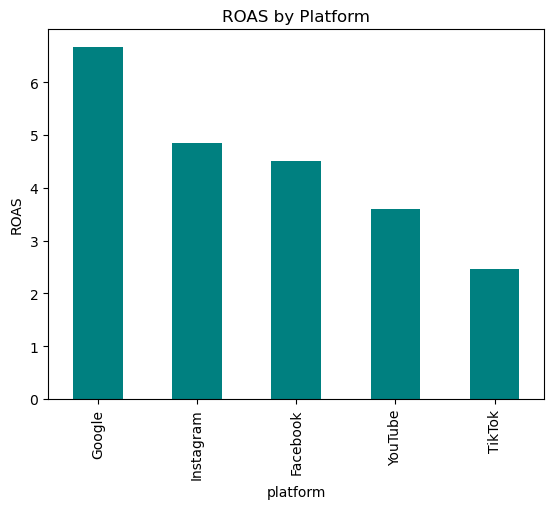

In [5]:
summary["ROAS"].plot(kind="bar", title="ROAS by Platform", color="teal")
plt.ylabel("ROAS"); plt.show()

In [6]:
for col in ["age", "gender", "city", "device"]:
    g = df.groupby(col)[["spend","revenue"]].sum()
    g["ROAS"] = g.revenue / g.spend
    print(g.sort_values("ROAS", ascending=False).round(2), "\n")

# Platform x device heatmap-style table
pt = df.pivot_table(index="platform", columns="device",
                    values=["revenue","spend"], aggfunc="sum")
(pt["revenue"] / pt["spend"]).round(2)

             spend       revenue  ROAS
age                                   
45-54  10744545.24  5.917636e+07  5.51
55+     5329457.13  2.920432e+07  5.48
25-34  35139495.28  1.916395e+08  5.45
35-44  20012235.29  1.088725e+08  5.44
18-24  29136808.30  1.565772e+08  5.37 

              spend       revenue  ROAS
gender                                 
Female  50818887.58  2.766625e+08  5.44
Male    49543653.66  2.688074e+08  5.43 

                  spend      revenue  ROAS
city                                      
Karachi     16229452.71  89309216.97  5.50
Faisalabad  16314884.00  89251522.56  5.47
Multan      16524235.57  89924041.52  5.44
Lahore      17144240.78  92951134.12  5.42
Islamabad   17410563.42  94336338.96  5.42
Peshawar    16739164.76  89697649.57  5.36 

               spend       revenue  ROAS
device                                  
Tablet    4756170.89  2.653523e+07  5.58
Desktop  25952304.56  1.446834e+08  5.57
Mobile   69654065.79  3.742513e+08  5.37 



device,Desktop,Mobile,Tablet
platform,,,
Facebook,4.61,4.47,4.26
Google,6.89,6.57,6.83
Instagram,4.94,4.80,5.20
TikTok,2.41,2.47,2.51
YouTube,3.60,3.60,3.72


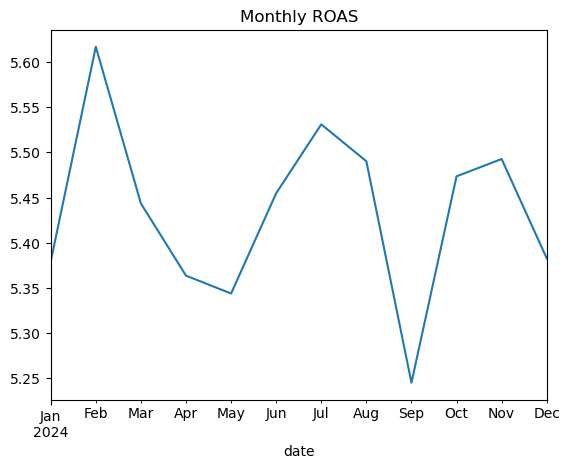

In [11]:
m = df.set_index("date").resample("ME")[["spend","revenue"]].sum()
(m.revenue / m.spend).plot(title="Monthly ROAS"); plt.show()

           ROAS  Share_%  Budget_Rs  Expected_Revenue
platform                                             
Google     6.66     27.1   271351.0         1808522.0
Instagram  4.86     21.4   213975.0         1038965.0
Facebook   4.50     20.3   202612.0          911189.0
YouTube    3.60     17.4   174248.0          627777.0
TikTok     2.45     13.8   137813.0          338165.0
Total expected revenue: 4724618.0


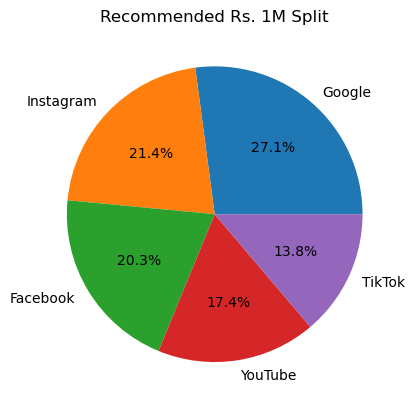

In [8]:
def recommend_budget(summary, total=1_000_000, blend=0.7):
    roas = summary["ROAS"]
    w_perf  = roas / roas.sum()
    w_equal = pd.Series(1/len(roas), index=roas.index)
    w = blend * w_perf + (1 - blend) * w_equal

    out = pd.DataFrame({
        "ROAS": roas.round(2),
        "Share_%": (w * 100).round(1),
        "Budget_Rs": (w * total).round(0),
    })
    out["Expected_Revenue"] = (out["Budget_Rs"] * roas).round(0)
    return out.sort_values("Share_%", ascending=False)

rec = recommend_budget(summary)
print(rec)
print("Total expected revenue:", rec["Expected_Revenue"].sum())

rec["Share_%"].plot(kind="pie", autopct="%1.1f%%", title="Recommended Rs. 1M Split")
plt.ylabel(""); plt.show()

In [9]:
import csv, os
from collections import defaultdict

COLS = ["platform","impressions","clicks","spend","conversions","revenue"]

def make_csv(n, path):
    first = True
    for start in range(0, n, 1_000_000):          # chunks mein, memory bachane ke liye
        chunk = generate_data(min(1_000_000, n - start), seed=start)[COLS]
        chunk.to_csv(path, mode="w" if first else "a", header=first, index=False)
        first = False

# 1) Pandas
def run_pandas(path):
    d = pd.read_csv(path)
    return d.groupby("platform")[COLS[1:]].sum()

# 2) MapReduce (pure Python simulation)
def run_mapreduce(path):
    # MAP: har row -> (key, values)
    def mapper(row):
        return row[0], tuple(float(x) for x in row[1:])
    # SHUFFLE: same key wale values ek jagah
    groups = defaultdict(list)
    with open(path) as f:
        r = csv.reader(f); next(r)
        for row in r:
            k, v = mapper(row)
            groups[k].append(v)
    # REDUCE: har key ke values ka sum
    return {k: [sum(col) for col in zip(*vals)] for k, vals in groups.items()}

# 3) Spark
def run_spark(path):
    from pyspark.sql import SparkSession
    spark = SparkSession.builder.master("local[*]").appName("ads").getOrCreate()
    sdf = spark.read.csv(path, header=True, inferSchema=True)
    res = sdf.groupBy("platform").sum().collect()
    return res

Spark failed: No module named 'pyspark'
Spark failed: No module named 'pyspark'
Spark failed: No module named 'pyspark'
         Pandas  MapReduce Spark
records                         
10000      0.02       0.04  None
100000     0.09       0.48  None
1000000    0.73       4.52  None


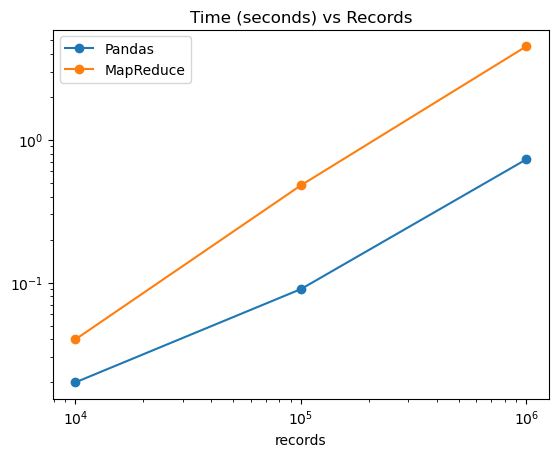

In [10]:
sizes = [10_000, 100_000, 1_000_000]      # 10M baad mein try karein (RAM 16GB+ ho to)
results = []
for n in sizes:
    path = f"ads_{n}.csv"
    make_csv(n, path)
    row = {"records": n}
    for name, fn in [("Pandas", run_pandas), ("MapReduce", run_mapreduce), ("Spark", run_spark)]:
        t = time.time()
        try:
            fn(path); row[name] = round(time.time() - t, 2)
        except Exception as e:
            row[name] = None; print(name, "failed:", e)
    results.append(row)
    os.remove(path)

bench = pd.DataFrame(results).set_index("records")
print(bench)
bench.plot(marker="o", logx=True, logy=True, title="Time (seconds) vs Records")
plt.show()

In [12]:
best_roas = summary["ROAS"].idxmax()
worst_roas = summary["ROAS"].idxmin()
lowest_cpa = summary["CPA"].idxmin()

print("=" * 50)
print("PROJECT SUMMARY: Digital Advertising Budget Optimizer")
print("=" * 50)
print(f"Total records analysed : {len(df):,}")
print(f"Total spend            : Rs. {df['spend'].sum():,.0f}")
print(f"Total revenue          : Rs. {df['revenue'].sum():,.0f}")
print(f"Overall ROAS           : {df['revenue'].sum() / df['spend'].sum():.2f}")

print(f"\nBest platform (ROAS)   : {best_roas} ({summary.loc[best_roas,'ROAS']:.2f})")
print(f"Worst platform (ROAS)  : {worst_roas} ({summary.loc[worst_roas,'ROAS']:.2f})")
print(f"Lowest CPA             : {lowest_cpa} (Rs. {summary.loc[lowest_cpa,'CPA']:.0f})")

print("\nBest segments by ROAS:")
for col in ["city", "device", "age", "gender"]:
    g = df.groupby(col)[["spend", "revenue"]].sum()
    r = (g.revenue / g.spend)
    print(f"  {col:7}: {r.idxmax()} ({r.max():.2f})")

print("\nRecommended split of Rs. 1,000,000:")
for p, row in rec.iterrows():
    print(f"  {p:10}: {row['Share_%']:>5.1f}%  = Rs. {row['Budget_Rs']:>10,.0f}")
print(f"\nExpected revenue : Rs. {rec['Expected_Revenue'].sum():,.0f}")
print(f"Expected ROAS    : {rec['Expected_Revenue'].sum() / 1_000_000:.2f}")

PROJECT SUMMARY: Digital Advertising Budget Optimizer
Total records analysed : 10,000
Total spend            : Rs. 100,362,541
Total revenue          : Rs. 545,469,904
Overall ROAS           : 5.43

Best platform (ROAS)   : Google (6.66)
Worst platform (ROAS)  : TikTok (2.45)
Lowest CPA             : Google (Rs. 603)

Best segments by ROAS:
  city   : Karachi (5.50)
  device : Tablet (5.58)
  age    : 45-54 (5.51)
  gender : Female (5.44)

Recommended split of Rs. 1,000,000:
  Google    :  27.1%  = Rs.    271,351
  Instagram :  21.4%  = Rs.    213,975
  Facebook  :  20.3%  = Rs.    202,612
  YouTube   :  17.4%  = Rs.    174,248
  TikTok    :  13.8%  = Rs.    137,813

Expected revenue : Rs. 4,724,618
Expected ROAS    : 4.72


In [14]:
print(bench)
print("Fastest at largest size:", bench.iloc[-1].idxmin())

         Pandas  MapReduce Spark
records                         
10000      0.02       0.04  None
100000     0.09       0.48  None
1000000    0.73       4.52  None
Fastest at largest size: Pandas


In [15]:
from IPython.display import Markdown, display

best, worst, low_cpa = summary["ROAS"].idxmax(), summary["ROAS"].idxmin(), summary["CPA"].idxmin()

def best_seg(col):
    s = df.groupby(col)[["spend", "revenue"]].sum()
    r = s.revenue / s.spend
    return r.idxmax(), r.max()

city, device, age = best_seg("city"), best_seg("device"), best_seg("age")
mm = df.set_index("date").resample("ME")[["spend", "revenue"]].sum()
mr = mm.revenue / mm.spend
total_spend, total_rev = df["spend"].sum(), df["revenue"].sum()
exp_rev = rec["Expected_Revenue"].sum()

rows = "\n".join(
    f"| {p} | {r['Share_%']:.1f}% | {r['Budget_Rs']:,.0f} | {r['ROAS']:.2f} |"
    for p, r in rec.iterrows()
)

last = bench.index[-1]
p_t, m_t = bench.loc[last, "Pandas"], bench.loc[last, "MapReduce"]
spark_ok = bench["Spark"].notna().any()
spark_line = (f"Spark took {bench.loc[last, 'Spark']:.2f} s on the same data."
              if spark_ok else
              "Spark could not be run in this environment, so it is not included in the comparison.")

md = f"""# Conclusion

## 1. Objective
Management needed to decide where to invest the next Rs. 1,000,000 across five advertising platforms: Facebook, Instagram, Google, TikTok and YouTube. A simulated dataset of {len(df):,} campaign records was created, and CTR, CPC, CPA, conversion rate and ROAS were calculated.

## 2. Key Findings
- Total spend was Rs. {total_spend:,.0f} and total revenue was Rs. {total_rev:,.0f}, giving an overall ROAS of {total_rev/total_spend:.2f}.
- **{best}** was the best platform (ROAS {summary.loc[best, 'ROAS']:.2f}) and **{worst}** was the weakest (ROAS {summary.loc[worst, 'ROAS']:.2f}).
- **{low_cpa}** had the lowest cost per acquisition (Rs. {summary.loc[low_cpa, 'CPA']:,.0f}).
- The best-performing segments were **{city[0]}** (city, ROAS {city[1]:.2f}), **{device[0]}** (device, ROAS {device[1]:.2f}) and the **{age[0]}** age group (ROAS {age[1]:.2f}).
- Monthly ROAS stayed between {mr.min():.2f} and {mr.max():.2f} throughout the year, so no strong trend was found.

## 3. Budget Recommendation (Rs. 1,000,000)
| Platform | Share | Budget (Rs.) | ROAS |
|---|---|---|---|
{rows}

The allocation is 70% based on ROAS and 30% split equally, so the budget is not concentrated in a single platform. Expected revenue is Rs. {exp_rev:,.0f}, an expected ROAS of {exp_rev/1_000_000:.2f}.

## 4. Pandas vs MapReduce vs Spark
At {last:,} records, Pandas took {p_t:.2f} s and MapReduce took {m_t:.2f} s, so Pandas was about {m_t/p_t:.1f} times faster. {spark_line}
- **Pandas:** fastest and simplest for small and medium data, but limited by available RAM.
- **MapReduce:** useful for understanding the map, shuffle and reduce idea, but the pure Python version is slow.
- **Spark:** has startup overhead on small data, but scales to very large data and clusters.

## 5. Limitations
- The data is simulated, so real campaigns would show seasonality, audience overlap and diminishing returns.
- The recommendation relies on past ROAS, which may fall as spend increases.

## 6. Future Improvements
- Use real campaign data.
- Model diminishing returns as budget grows.
- Use linear programming to optimise the split.
"""

display(Markdown(md))

# Conclusion

## 1. Objective
Management needed to decide where to invest the next Rs. 1,000,000 across five advertising platforms: Facebook, Instagram, Google, TikTok and YouTube. A simulated dataset of 10,000 campaign records was created, and CTR, CPC, CPA, conversion rate and ROAS were calculated.

## 2. Key Findings
- Total spend was Rs. 100,362,541 and total revenue was Rs. 545,469,904, giving an overall ROAS of 5.43.
- **Google** was the best platform (ROAS 6.66) and **TikTok** was the weakest (ROAS 2.45).
- **Google** had the lowest cost per acquisition (Rs. 603).
- The best-performing segments were **Karachi** (city, ROAS 5.50), **Tablet** (device, ROAS 5.58) and the **45-54** age group (ROAS 5.51).
- Monthly ROAS stayed between 5.25 and 5.62 throughout the year, so no strong trend was found.

## 3. Budget Recommendation (Rs. 1,000,000)
| Platform | Share | Budget (Rs.) | ROAS |
|---|---|---|---|
| Google | 27.1% | 271,351 | 6.66 |
| Instagram | 21.4% | 213,975 | 4.86 |
| Facebook | 20.3% | 202,612 | 4.50 |
| YouTube | 17.4% | 174,248 | 3.60 |
| TikTok | 13.8% | 137,813 | 2.45 |

The allocation is 70% based on ROAS and 30% split equally, so the budget is not concentrated in a single platform. Expected revenue is Rs. 4,724,618, an expected ROAS of 4.72.

## 4. Pandas vs MapReduce vs Spark
At 1,000,000 records, Pandas took 0.73 s and MapReduce took 4.52 s, so Pandas was about 6.2 times faster. Spark could not be run in this environment, so it is not included in the comparison.
- **Pandas:** fastest and simplest for small and medium data, but limited by available RAM.
- **MapReduce:** useful for understanding the map, shuffle and reduce idea, but the pure Python version is slow.
- **Spark:** has startup overhead on small data, but scales to very large data and clusters.

## 5. Limitations
- The data is simulated, so real campaigns would show seasonality, audience overlap and diminishing returns.
- The recommendation relies on past ROAS, which may fall as spend increases.

## 6. Future Improvements
- Use real campaign data.
- Model diminishing returns as budget grows.
- Use linear programming to optimise the split.
